# Учебное исследование Минусинска с BlocksNet

Территория: Минусинск, Красноярский край, Россия. Ноутбук подготовлен по `examples/pipeline.ipynb` из BlocksNet `1.0.0.a9`. Он содержит получение данных и расчёты, но ничего не запускает автоматически.

Важно: в официальном хранилище готовых данных BlocksNet опубликованы данные Санкт-Петербурга, готового графа Минусинска там нет. Поэтому выбран пешеходный граф `walk` из OpenStreetMap через IduEdu `0.4.1`. Он будет получен по запросу Overpass только если вы запустите соответствующую ячейку, затем сохранён локально для повторного использования. Это не интермодальный граф.

Источники: [пример pipeline](https://github.com/aimclub/blocksnet/blob/v1.0.0.a9/examples/pipeline.ipynb), [репозиторий BlocksNet-data](https://github.com/IDUclub/blocksnet-data), [документация IduEdu](https://iduclub.github.io/IduEdu/). Данные OpenStreetMap доступны по лицензии ODbL.

## 1. Подготовка Windows

Текущий Python VS Code — 3.14, а закреплённый BlocksNet зависит от IduEdu `0.4.1`, которому нужен Python `3.10–3.12`. Создайте отдельное окружение с Python 3.12. В PowerShell из корня проекта выполните команды по очереди.

Сначала убедитесь, что Python 3.12 установлен: `py --list`. Если версии 3.12 нет, установите Python 3.12 с python.org, затем перезапустите VS Code.

```powershell
py -3.12 -m venv .venv-blocksnet
.\.venv-blocksnet\Scripts\python.exe -m pip install --upgrade pip
.\.venv-blocksnet\Scripts\python.exe -m pip install -e ".[dev]"
.\.venv-blocksnet\Scripts\python.exe -m pip install "blocksnet[ipynb]==1.0.0a9"
.\.venv-blocksnet\Scripts\python.exe -m ipykernel install --user --name blocksnet-1-0-0a9 --display-name "Python 3.12 (BlocksNet 1.0.0a9)"
```

`.[dev]` использует зависимости notebook из существующего `pyproject.toml`; устанавливать пакеты в это окружение сейчас не нужно. Затем откройте notebook и выберите ядро `Python 3.12 (BlocksNet 1.0.0a9)`.

In [1]:
import sys
from importlib.metadata import version
from importlib.metadata import PackageNotFoundError

print("Python:", sys.version.split()[0])
try:
    blocksnet_version = version("blocksnet")
except PackageNotFoundError as exc:
    raise RuntimeError(
        f"BlocksNet не установлен в текущем ядре: {sys.executable}\n"
        'Выберите ядро "Python 3.12 (BlocksNet 1.0.0a9)" в VS Code.'
    ) from exc

print("BlocksNet:", blocksnet_version)
print("IduEdu:", version("iduedu"))

assert (3, 10) <= sys.version_info[:2] < (3, 13), "Для IduEdu 0.4.1 нужен Python 3.10-3.12. Выберите правильное ядро."
assert version("blocksnet") == "1.0.0a9", "Нужен BlocksNet 1.0.0.a9. Проверьте выбранное ядро."
assert version("iduedu") == "0.4.1", "Проверьте версию IduEdu, установленную вместе с BlocksNet."

Python: 3.12.0
BlocksNet: 1.0.0a9
IduEdu: 0.4.1


## 2. Как работать с notebook

Выполняйте ячейки сверху вниз кнопкой запуска текущей ячейки. **Не используйте «Run All»**: в конце подготовки кварталов есть намеренная остановка. После неё расчётный этап закрыт переключателем `RUN_ANALYSIS = False`; до обсуждения метрик оставьте его выключенным.

Ячейки проверяют наличие готовых GeoJSON и графа и читают их, если файлы уже сохранены. Загрузки из OpenStreetMap происходят только при ручном запуске ячеек, когда соответствующего файла ещё нет.

In [1]:
from enum import Enum
from pathlib import Path

import geopandas as gpd
import networkx as nx
import osmnx as ox
import pandas as pd

from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.analysis.provision import competitive_provision
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.cutting import cut_urban_blocks, preprocess_urban_objects
from blocksnet.config import service_types_config
from blocksnet.enums import LandUse
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.relations import calculate_accessibility_matrix, get_accessibility_graph

c:\Users\User\ai-course\python-package-boilerplate\.venv-blocksnet\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
PLACE_QUERY = "Минусинск, Красноярский край, Россия"
DATA_DIR = Path("data") / "minusinsk"
DATA_DIR.mkdir(parents=True, exist_ok=True)
BOUNDARY_FILE = DATA_DIR / "boundary.geojson"
BLOCKS_FILE = DATA_DIR / "blocks.geojson"
GRAPH_FILE = DATA_DIR / "minusinsk_walk.graphml"
MATRIX_FILE = DATA_DIR / "accessibility_walk_minutes.csv"

def save_geojson(layer, path):
    export_layer = layer.copy()
    for column in export_layer.select_dtypes(include=["object"]).columns:
        export_layer[column] = export_layer[column].map(
            lambda value: value.value if isinstance(value, Enum) else value
        )
    export_layer.to_crs(4326).to_file(path, driver="GeoJSON", index=True)

def load_or_fetch_geojson(path, fetch_function, target_crs):
    if path.exists():
        print(f"Читаю готовый файл: {path}")
        return gpd.read_file(path).to_crs(target_crs)
    print(f"Файл {path} не найден; данные будут запрошены при выполнении этой ячейки.")
    layer = fetch_function().reset_index(drop=True)
    save_geojson(layer, path)
    return layer.to_crs(target_crs)

## 3. Границы и кварталообразующие данные

Границы ищутся по названию через OpenStreetMap Nominatim. Для расчёта площадей используется местная метрическая проекция UTM. Слои сохраняются в GeoJSON; при следующем запуске будут прочитаны с диска.

In [3]:
if BOUNDARY_FILE.exists():
    boundaries_wgs84 = gpd.read_file(BOUNDARY_FILE).to_crs(4326)
else:
    boundaries_wgs84 = ox.geocode_to_gdf(PLACE_QUERY).iloc[[0]].copy()
    save_geojson(boundaries_wgs84, BOUNDARY_FILE)

analysis_crs = boundaries_wgs84.estimate_utm_crs()
boundaries = boundaries_wgs84.to_crs(analysis_crs)
print("Проекция для измерений:", analysis_crs)
display(boundaries[["geometry"]])

Проекция для измерений: EPSG:32646


,geometry
0,"POLYGON ((408977.413 5954805.905, 409084.74 59..."


Для нарезки BlocksNet нужны линии улиц и железных дорог, полигоны/линии воды и внешняя граница. Эта ячейка проверяет каждый GeoJSON отдельно, поэтому уже загруженный слой повторно не запрашивается.

In [7]:
bc_tags = {
    "roads": {"highway": ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified", "living_street", "pedestrian", "service", "track", "road"]},
    "railways": {"railway": ["rail", "light_rail", "subway", "tram"]},
    "water": {"natural": ["water", "bay"], "waterway": ["river", "canal", "ditch"], "landuse": "basin", "water": ["lake", "reservoir"]},
}
boundary_polygon = boundaries_wgs84.geometry.union_all()

water = load_or_fetch_geojson(
    DATA_DIR / "water.geojson",
    lambda: ox.features_from_polygon(boundary_polygon, bc_tags["water"]),
    analysis_crs,
).loc[lambda data: data.geom_type.isin(["Polygon", "MultiPolygon", "LineString", "MultiLineString"])].copy()
roads = load_or_fetch_geojson(
    DATA_DIR / "roads.geojson",
    lambda: ox.features_from_polygon(boundary_polygon, bc_tags["roads"]),
    analysis_crs,
).loc[lambda data: data.geom_type.isin(["LineString", "MultiLineString"])].copy()

RAILWAYS_FILE = DATA_DIR / "railways.geojson"
FETCH_RAILWAYS_FROM_OSM = False

if RAILWAYS_FILE.exists():
    railways = gpd.read_file(RAILWAYS_FILE).to_crs(analysis_crs)
    print("Читаю сохранённые железные дороги:", RAILWAYS_FILE)
elif FETCH_RAILWAYS_FROM_OSM:
    from osmnx._errors import InsufficientResponseError

    try:
        railways = ox.features_from_polygon(boundary_polygon, bc_tags["railways"]).reset_index(drop=True)
    except InsufficientResponseError:
        print("Железные дороги в OSM не найдены; использую пустой слой.")
        railways = gpd.GeoDataFrame(
            geometry=gpd.GeoSeries([], crs=analysis_crs),
            crs=analysis_crs,
        )
    else:
        if railways.empty:
            print("Железные дороги в OSM не найдены; использую пустой слой.")
            railways = gpd.GeoDataFrame(
                geometry=gpd.GeoSeries([], crs="EPSG:4326"),
                crs="EPSG:4326",
            )
        else:
            save_geojson(railways, RAILWAYS_FILE)
        railways = railways.to_crs(analysis_crs)
else:
    print("Запрос железных дорог отключён; использую пустой слой.")
    railways = gpd.GeoDataFrame(
        geometry=gpd.GeoSeries([], crs=analysis_crs),
        crs=analysis_crs,
    )

railways = railways.loc[
    railways.geom_type.isin(["LineString", "MultiLineString"])
].copy()

print("Объектов воды:", len(water))
print("Дорожных линий:", len(roads))
print("Железнодорожных линий:", len(railways))

Читаю готовый файл: data\minusinsk\water.geojson
Читаю готовый файл: data\minusinsk\roads.geojson
Запрос железных дорог отключён; использую пустой слой.
Объектов воды: 22
Дорожных линий: 2050
Железнодорожных линий: 0


## 4. Подготовка кварталов

BlocksNet приводит линейные и полигональные объекты к нужным схемам, затем разрезает территорию по уличной сети и исключает водные/неподходящие участки. Результат сохраняется как `blocks.geojson`. Если файл уже есть, пропустите обработку и загрузите его из файла.

2026-10-31 01:16:09.556 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-31 01:16:09.611 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-31 01:16:09.613 | WARNING  | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:53 - Creating empty railways
2026-10-31 01:16:09.623 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-31 01:16:09.662 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-31 01:16:09.696 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-31 01:16:09.720 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-31 01:16:09.754 | INFO

Число кварталов: 1721


,geometry
block_id,
0,"POLYGON ((412553.001 5950474.934, 412532.586 5..."
1,"POLYGON ((412532.586 5950457.91, 412553.001 59..."
2,"POLYGON ((412530.376 5950456.282, 412532.586 5..."
3,"POLYGON ((412530.376 5950456.282, 412475.695 5..."
4,"POLYGON ((412475.695 5950412.932, 412530.376 5..."


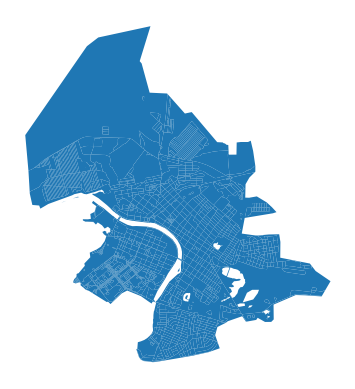

In [8]:
if BLOCKS_FILE.exists():
    blocks = gpd.read_file(BLOCKS_FILE).to_crs(analysis_crs)
    if "block_id" in blocks.columns:
        blocks = blocks.set_index("block_id")
else:
    lines, polygons = preprocess_urban_objects(roads, railways, water)
    blocks = cut_urban_blocks(boundaries, lines, polygons).reset_index(drop=True)
    blocks.index.name = "block_id"
    save_geojson(blocks, BLOCKS_FILE)

blocks.index.name = "block_id"
print("Число кварталов:", len(blocks))
display(blocks.head())
blocks.plot().set_axis_off()

## СТОП: проверьте кварталы и обсудите метрики

На этом закончена подготовка геометрии. Посмотрите карту и число кварталов. **Не запускайте расчётный раздел, пока не обсудите со мной доступные метрики.** В pipeline предусмотрены: функциональное использование, параметры зданий и население, вместимость школ, матрица времени доступности, конкурентная обеспеченность школ, показатели Spacematrix (`FSI`, `GSI`, `MXI`, `L`, `OSR` и доли площадей), морфотипы Spacematrix и Стрелки, взвешенная площадью доступность.

Расчётный раздел дополнительно закрыт переменной `RUN_ANALYSIS = False`. После нашего согласования переключите её в `True`.

## Какие метрики есть в BlocksNet?

### Простыми словами

BlocksNet описывает город по кварталам: какие функции занимают территорию, сколько в ней зданий и жителей, сколько времени занимает путь между кварталами, хватает ли вместимости школ, какова плотность застройки и к какому типу она относится. Это не один универсальный «балл города», а набор показателей для разных вопросов.

### Все показатели и выходы из `examples/pipeline.ipynb`

#### 1. Функции квартала

- `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` — доля площади квартала, перекрытая объектами соответствующей функции. Единица: доля от 0 до 1; например, `0.25` соответствует 25% площади. Сумма может быть меньше 1, если часть квартала не описана данными OSM.
- `land_use` — преобладающая функция квартала, категория без единиц измерения.
- `share` — доля преобладающей функции, безразмерная величина.

Эти поля помогают увидеть жилые, деловые, промышленные и смешанные части Минусинска, а также пробелы в исходных данных.

#### 2. Здания и население

- `is_living` — признак жилого здания, `True`/`False`.
- `number_of_floors` — число этажей, этажи.
- `footprint_area` — площадь пятна здания, м².
- `build_floor_area` — суммарная площадь этажей, м².
- `living_area` и `non_living_area` — оценённые жилые и нежилые площади, м².
- `population` — оценка числа жителей, человек. Это расчётная оценка BlocksNet по имеющимся данным, а не перепись населения.
- `objects_count` в агрегированном слое зданий — число зданий в квартале, шт.

Показатели покажут, где сосредоточены жильё и расчётное население, насколько полны сведения о зданиях и как распределены площади.

#### 3. Школы и конкурентная обеспеченность

- `capacity` — вместимость школ, человеко-места; `objects_count` — число школьных объектов, шт.
- `demand` — расчётная потребность в школьных местах, человеко-места. Она оценивается по населению и нормативу BlocksNet на 1000 жителей.
- `demand_left`, `demand_within`, `demand_without` — неудовлетворённая потребность, обслуженная в пределах порога времени и обслуженная за его пределами; человеко-места.
- `capacity_left`, `capacity_within`, `capacity_without` — свободная вместимость, использованная в пределах порога и использованная за его пределами; человеко-места.
- `provision_strong` — доля потребности, обслуженная в пределах заданного времени, от 0 до 1.
- `provision_weak` — доля потребности, обслуженная в пределах времени или за его пределами в рамках поиска, от 0 до 1.
- `links_df`: `source` и `target` — кварталы спроса и школы, `value` — распределённый между ними спрос, человеко-места.

Это помогает найти кварталы, где не хватает школьных мест или где путь до школы превышает выбранный порог. Порог и норматив берутся из `service_types_config["school"]`.

#### 4. Пешеходная доступность

- `acc_mx` — матрица времени пути между центрами кварталов по графу `walk`; минуты. Строки и столбцы — `block_id`.
- `area_accessibility` — среднее время пути до квартала, взвешенное площадью кварталов назначения; минуты. Меньшее значение означает, что квартал в среднем ближе к остальной территории по сети.

Карта выявит районы, связанные с городом хуже или лучше остальных. Это не время до конкретной школы и не расстояние по прямой.

#### 5. Плотность застройки

Перед расчётом используются `site_area` (площадь квартала), `footprint_area` (сумма пятен зданий), `build_floor_area`, `living_area` и `non_living_area`; площади измеряются в м².

- `FSI` (`fsi`) = площадь всех этажей / площадь квартала. Безразмерный коэффициент: показывает интенсивность использования земли.
- `GSI` (`gsi`) = площадь пятен зданий / площадь квартала. Безразмерная доля от 0 до 1: показывает, какая часть земли занята зданиями.
- `MXI` (`mxi`) = жилая площадь / площадь всех этажей. Безразмерная доля от 0 до 1. В этой версии это доля жилья, а не общий индекс разнообразия городских функций.
- `L` (`l`) = площадь всех этажей / площадь пятен зданий. Безразмерное отношение, интерпретируемое примерно как среднее число этажей.
- `OSR` (`osr`) = открытая площадь квартала / площадь всех этажей. Безразмерное отношение; выше — больше открытого пространства относительно объёма застройки.
- `share_living`, `share_non_living` — жилая и нежилая площади, делённые на площадь пятен зданий; безразмерные коэффициенты. По формулам версии 1.0.0.a9 это не доли, которые обязаны суммироваться в 1.

Вместе эти показатели описывают плотность, высотность и баланс жилой/нежилой застройки. Для кварталов без зданий некоторые значения будут неопределёнными.

#### 6. Морфотипы

- `spacematrix_df`: `cluster` — номер группы без единиц; `morphotype` — словесный тип, сформированный по значениям `L`, `FSI` и `MXI`.
- `spacematrix_clusters` — сводка по группам: медианные `L`, `FSI`, `MXI`, интерпретации и название типа.
- `strelka_df.morphotype` — категория типа застройки Стрелки, определённая по `L`, `FSI` и `MXI`.

Это позволит сравнить кварталы Минусинска по структуре застройки. Названия классов — классификация, а не физическая единица измерения.

### Что будет видно на выходе

Pipeline показывает таблицы и карты функций кварталов, населения, вместимости школ, сильной обеспеченности школами, двух классификаций морфотипов и взвешенного времени доступности; также сохраняет итоговые таблицы и связи между кварталами. Выводы относятся к данным OSM и будут ограничены полнотой этих данных.

**Расчётные ячейки остаются за переключателем `RUN_ANALYSIS = False`. Не включайте его до согласования показателей и порога доступности.**

In [10]:
RUN_ANALYSIS = True

## 5. Расчёты после согласования метрик

Все следующие вычисления выполняются только при `RUN_ANALYSIS = True`. OSM-слои функционального использования, зданий и школ тоже загружаются лишь при ручном запуске расчётной ячейки, если соответствующих GeoJSON ещё нет.

### Подготовка функциональных зон

Для Минусинска не следует считать `landuse` из OpenStreetMap полным или официальным функциональным зонированием. OSM может быть неполным и устаревшим; ошибка `502` означает сбой/перегрузку сервиса, а не подтверждение отсутствия объектов. Для анализа предпочтительны цифровые данные генерального плана, ПЗЗ или муниципальной GIS. Если доступна только карта в PDF/скане, её можно геопривязать в QGIS и оцифровать границы зон. Не нужно вручную размечать каждое здание: оцифровывайте полигоны функциональных зон, насколько позволяет источник.

#### Файл и геометрия

Сохраните подготовленный слой как `data/minusinsk/functional_zones.geojson` относительно папки проекта. Геометрия должна быть полигональной (`Polygon`/`MultiPolygon`), с известной системой координат. В QGIS используйте **Экспорт → Сохранить объекты как… → GeoJSON**; можно сохранить в EPSG:4326. Ноутбук перепроецирует слой в рабочую UTM-систему. Исправьте ошибки геометрии, удалите пустые объекты и проверьте, что слой действительно покрывает Минусинск.

В таблице атрибутов обязательно создайте текстовое поле `functional_zone`. Исходное поле `Landuse` можно сохранить для аудита, а его значения привести к классам BlocksNet. Поддерживаемые классы: `residential` (жилой), `business` (общественно-деловой), `industrial` (производственный/промышленный), `recreation` (рекреационный/озеленённый), `transport` (транспортный), `special` (специального назначения), `agriculture` (сельскохозяйственный). Если исходные категории называются иначе, сопоставьте их в поле `functional_zone` либо добавьте точные исходные названия в словарь `rules` в расчётной ячейке. Не объединяйте категории автоматически, если это меняет смысл генерального плана; сохраните оригинальную категорию в отдельном поле.

#### Проверки перед расчётом

Избегайте перекрытий зон: BlocksNet определяет класс квартала по наибольшей площади пересечения, а перекрывающиеся полигоны могут исказить доли. Непокрытые участки допустимы, но кварталы без подходящего пересечения останутся без `land_use`; это следует учитывать как пробел исходных данных, а не как «нежилую» функцию. Зафиксируйте источник и дату слоя, например в полях `source` и `source_year`.

В ячейке локальный файл имеет приоритет. Переключатель `USE_OSM_FUNCTIONAL_ZONES = False` оставляет запросы к OSM выключенными. Включайте его только для ознакомительного OSM-варианта; если файл не подготовлен и переключатель выключен, ячейка остановится с понятной инструкцией вместо сетевого запроса. Пока источник и классы не проверены, оставьте `RUN_ANALYSIS = False`.

2026-10-31 02:19:12.138 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: allotments


Читаю локальные функциональные зоны: data\minusinsk\functional_zones.geojson
Не сопоставленные категории будут исключены: ['allotments'] Добавьте точные значения в словарь rules.


,geometry,residential,business,recreation,industrial,transport,special,agriculture,land_use,share
0,"POLYGON ((412553.001 5950474.934, 412532.586 5...",0.0,0.0,0.000000,0.0,0.0,0.0,0.0,None,NaN
1,"POLYGON ((412532.586 5950457.91, 412553.001 59...",0.0,0.0,0.000000,0.0,0.0,0.0,0.0,None,NaN
2,"POLYGON ((412530.376 5950456.282, 412532.586 5...",0.0,0.0,0.263979,0.0,0.0,0.0,0.0,LandUse.RECREATION,0.263979
3,"POLYGON ((412530.376 5950456.282, 412475.695 5...",0.0,0.0,0.000000,0.0,0.0,0.0,0.0,None,NaN
4,"POLYGON ((412475.695 5950412.932, 412530.376 5...",0.0,0.0,0.559518,0.0,0.0,0.0,0.0,LandUse.RECREATION,0.559518


TypeError: '<' not supported between instances of 'LandUse' and 'LandUse'

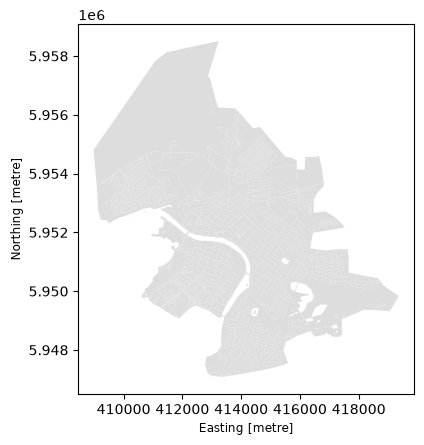

In [ ]:
if RUN_ANALYSIS:
    FUNCTIONAL_ZONES_FILE = DATA_DIR / "functional_zones.geojson"
    USE_OSM_FUNCTIONAL_ZONES = False

    if FUNCTIONAL_ZONES_FILE.exists():
        functional_zones = gpd.read_file(FUNCTIONAL_ZONES_FILE).to_crs(analysis_crs)
        print("Читаю локальные функциональные зоны:", FUNCTIONAL_ZONES_FILE)
    elif USE_OSM_FUNCTIONAL_ZONES:
        print("Локальный слой не найден; запрашиваю landuse из OSM.")
        functional_zones = ox.features_from_polygon(
            boundary_polygon, tags={"landuse": True}
        ).reset_index(drop=True)
        functional_zones = functional_zones.rename(
            columns={"landuse": "functional_zone"}
        )
        save_geojson(functional_zones, FUNCTIONAL_ZONES_FILE)
        functional_zones = functional_zones.to_crs(analysis_crs)
    else:
        raise FileNotFoundError(
            f"Не найден слой {FUNCTIONAL_ZONES_FILE}. Подготовьте GeoJSON с полигональной "
            "геометрией и полем functional_zone по инструкции выше, либо явно включите "
            "USE_OSM_FUNCTIONAL_ZONES для ознакомительного запроса к OSM."
        )

    if "functional_zone" not in functional_zones.columns:
        source_column = next(
            (column for column in ["Landuse", "landuse", "land_use"] if column in functional_zones.columns),
            None,
        )
        if source_column is None:
            raise ValueError(
                "В слое требуется поле functional_zone (допустимые исходные имена: "
                "Landuse, landuse, land_use). Переименуйте поле или подготовьте GeoJSON заново."
            )
        functional_zones = functional_zones.rename(
            columns={source_column: "functional_zone"}
        )

    functional_zones = functional_zones.loc[
        functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
    ].copy()
    if functional_zones.empty:
        raise ValueError(
            "В слое функциональных зон нет полигонов. Проверьте геометрию GeoJSON."
        )
    functional_zones["functional_zone"] = (
        functional_zones["functional_zone"].astype("string").str.strip().str.lower()
    )
    functional_zones = functional_zones.dropna(subset=["functional_zone"])

    rules = {
        "commercial": LandUse.BUSINESS,
        "retail": LandUse.BUSINESS,
        "industrial": LandUse.INDUSTRIAL,
        "garages": LandUse.INDUSTRIAL,
        "residential": LandUse.RESIDENTIAL,
        "grass": LandUse.RECREATION,
        "forest": LandUse.RECREATION,
        "recreation_ground": LandUse.RECREATION,
        "farmland": LandUse.AGRICULTURE,
        "cemetery": LandUse.SPECIAL,
        "construction": LandUse.SPECIAL,
        "brownfield": LandUse.INDUSTRIAL,
        "religious": LandUse.SPECIAL,
        "military": LandUse.SPECIAL,
        "landfill": LandUse.TRANSPORT,
    }
    unmapped_zones = set(functional_zones["functional_zone"].unique()) - set(rules)
    if unmapped_zones:
        print(
            "Не сопоставленные категории будут исключены:",
            sorted(unmapped_zones),
            "Добавьте точные значения в словарь rules.",
        )

    blocks = assign_land_use(blocks, functional_zones, rules)
    save_geojson(blocks, DATA_DIR / "blocks_land_use.geojson")
    display(blocks.head())
    land_use_plot = blocks.copy()
    land_use_plot["land_use_label"] = blocks["land_use"].map(
        lambda value: value.value if isinstance(value, LandUse) else value
    ).fillna("Нет данных")
    ax = blocks.plot(color="#dddddd")
    land_use_plot.plot(
        column="land_use_label",
        legend=True,
        legend_kwds={"title": "Функциональная зона"},
        ax=ax,
    ).set_axis_off()
else:
    print("Пауза: RUN_ANALYSIS = False. Расчёты не выполняются.")

### Здания: площади и оценка населения

`impute_buildings` заполняет недостающие характеристики по правилам BlocksNet. Значение `default_living_demand=30` взято из pipeline; фактическое качество оценки зависит от полноты тегов OSM.

2026-10-31 02:39:35.787 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-31 02:39:35.787 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-31 02:39:35.787 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-31 02:39:35.787 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-31 02:39:35.787 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


Пересоздаю кэш зданий: в исходном слое есть жилые здания.


2026-10-31 02:39:36.641 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-31 02:39:36.661 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Оценка населения по зданиям: 48464


,geometry,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,count
0,"POLYGON ((412553.001 5950474.934, 412532.586 5...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,"POLYGON ((412532.586 5950457.91, 412553.001 59...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,"POLYGON ((412530.376 5950456.282, 412532.586 5...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,"POLYGON ((412530.376 5950456.282, 412475.695 5...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,"POLYGON ((412475.695 5950412.932, 412530.376 5...",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


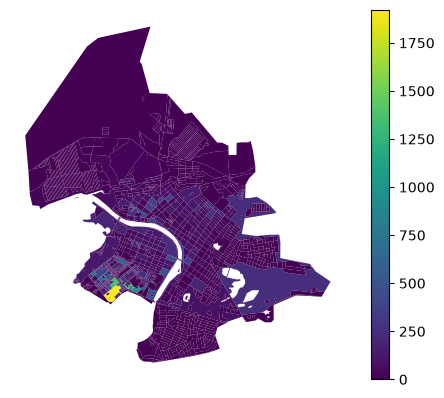

In [16]:
if RUN_ANALYSIS:
    PREPARED_BUILDINGS_FILE = DATA_DIR / "buildings_prepared.geojson"
    AGGREGATED_BUILDINGS_FILE = DATA_DIR / "blocks_buildings.geojson"
    BUILDINGS_FILE = DATA_DIR / "buildings.geojson"
    living_tags = {"residential", "house", "apartments", "detached", "terrace", "dormitory"}
    rebuild_prepared = not PREPARED_BUILDINGS_FILE.exists()

    if rebuild_prepared:
        buildings = load_or_fetch_geojson(
            BUILDINGS_FILE,
            lambda: ox.features_from_polygon(
                boundary_polygon, tags={"building": True}
            ).reset_index(drop=True),
            analysis_crs,
        )
    else:
        buildings = gpd.read_file(PREPARED_BUILDINGS_FILE).to_crs(analysis_crs)
        if BUILDINGS_FILE.exists():
            source_buildings = gpd.read_file(BUILDINGS_FILE).to_crs(analysis_crs)
            source_building_column = next(
                (column for column in source_buildings.columns if column.casefold() == "building"),
                None,
            )
            if source_building_column is not None:
                source_is_living = (
                    source_buildings[source_building_column]
                    .astype("string")
                    .str.strip()
                    .str.lower()
                    .isin(living_tags)
                )
                prepared_has_living = (
                    buildings["is_living"].fillna(False).astype(bool).any()
                    if "is_living" in buildings.columns
                    else False
                )
                if source_is_living.any() and not prepared_has_living:
                    print("Пересоздаю кэш зданий: в исходном слое есть жилые здания.")
                    buildings = source_buildings
                    rebuild_prepared = True

    if rebuild_prepared:
        building_column = next(
            (column for column in buildings.columns if column.casefold() == "building"),
            None,
        )
        if building_column is not None:
            buildings["is_living"] = (
                buildings[building_column]
                .astype("string")
                .str.strip()
                .str.lower()
                .isin(living_tags)
            )
        else:
            buildings["is_living"] = False

        levels_column = next(
            (column for column in buildings.columns if column.casefold() in {"building:levels", "b_levels"}),
            None,
        )
        levels = (
            buildings[levels_column]
            if levels_column is not None
            else pd.Series(index=buildings.index, dtype=object)
        )
        buildings["number_of_floors"] = pd.to_numeric(levels, errors="coerce")
        buildings = impute_buildings(buildings, default_living_demand=30)
        save_geojson(buildings, PREPARED_BUILDINGS_FILE)

    if AGGREGATED_BUILDINGS_FILE.exists() and not rebuild_prepared:
        buildings_blocks = gpd.read_file(AGGREGATED_BUILDINGS_FILE).to_crs(analysis_crs)
        if "block_id" in buildings_blocks.columns:
            buildings_blocks = buildings_blocks.set_index("block_id")
        buildings_blocks = buildings_blocks.reindex(blocks.index)
    else:
        buildings_blocks = aggregate_objects(blocks, buildings)[0]
        buildings_blocks.index = blocks.index
        save_geojson(buildings_blocks, AGGREGATED_BUILDINGS_FILE)
    print("Оценка населения по зданиям:", round(buildings["population"].sum()))
    display(buildings_blocks.head())
    buildings_blocks.plot("population", legend=True).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Школы и детские сады: вместимость по кварталам

Если отдельного слоя учреждений нет, ячейка выделяет объекты `school` и `kindergarten` из атрибута `BUILDING` в локальном `buildings.geojson`, сохраняет подготовленные объекты в `schools_prepared.geojson` и `kindergartens_prepared.geojson`, а агрегаты по кварталам — в `blocks_schools.geojson` и `blocks_kindergartens.geojson`. Если школы в слое зданий не найдены, ячейка использует локальный `schools.geojson`, а затем при его отсутствии запрашивает школы в OSM. Детские сады при отсутствии в слое зданий в этой версии не загружаются автоматически.

`impute_services` заполняет пропущенную вместимость минимальными значениями конфигурации BlocksNet (для текущей версии: 250 мест на школу и 80 мест на детский сад). Это модельное допущение, а не сведения о фактической вместимости учреждения. Если доступны официальные данные о числе мест, добавьте их в поле `capacity` перед расчётом. В агрегатах поле `objects_count` показывает число объектов каждого типа в квартале.

2026-10-31 03:05:08.677 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-31 03:05:08.690 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Найдено школ в слое зданий: 22
Найдено детских садов в слое зданий: 22


2026-10-31 03:05:08.877 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-31 03:05:08.877 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Сохранены подготовленные детские сады: data\minusinsk\kindergartens_prepared.geojson
Сохранены детские сады по кварталам: data\minusinsk\blocks_kindergartens.geojson


,capacity,objects_count
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0


Сохранены подготовленные школы: data\minusinsk\schools_prepared.geojson
Сохранены школы по кварталам: data\minusinsk\blocks_schools.geojson


,capacity,objects_count
0,0.0,0.0
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,0.0,0.0


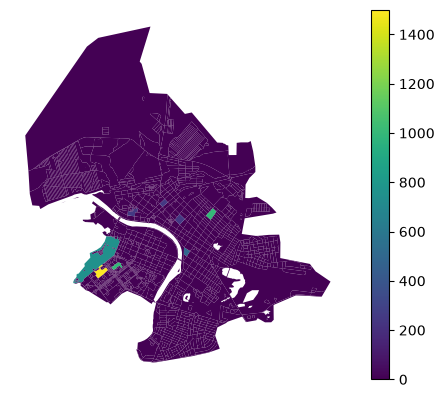

In [18]:
if RUN_ANALYSIS:
    BUILDINGS_FILE = DATA_DIR / "buildings.geojson"
    SCHOOLS_FILE = DATA_DIR / "schools.geojson"
    KINDERGARTENS_FILE = DATA_DIR / "kindergartens.geojson"
    PREPARED_SCHOOLS_FILE = DATA_DIR / "schools_prepared.geojson"
    PREPARED_KINDERGARTENS_FILE = DATA_DIR / "kindergartens_prepared.geojson"
    AGGREGATED_SCHOOLS_FILE = DATA_DIR / "blocks_schools.geojson"
    AGGREGATED_KINDERGARTENS_FILE = DATA_DIR / "blocks_kindergartens.geojson"

    schools = gpd.GeoDataFrame(geometry=gpd.GeoSeries([], crs=analysis_crs), crs=analysis_crs)
    kindergartens = gpd.GeoDataFrame(geometry=gpd.GeoSeries([], crs=analysis_crs), crs=analysis_crs)

    if BUILDINGS_FILE.exists():
        building_objects = gpd.read_file(BUILDINGS_FILE).to_crs(analysis_crs)
        building_column = next(
            (column for column in building_objects.columns if column.casefold() == "building"),
            None,
        )
        if building_column is not None:
            building_types = (
                building_objects[building_column]
                .astype("string")
                .str.strip()
                .str.lower()
            )
            schools = building_objects.loc[building_types == "school"].copy()
            kindergartens = building_objects.loc[building_types == "kindergarten"].copy()
            print("Найдено школ в слое зданий:", len(schools))
            print("Найдено детских садов в слое зданий:", len(kindergartens))

    if schools.empty:
        if SCHOOLS_FILE.exists():
            schools = gpd.read_file(SCHOOLS_FILE).to_crs(analysis_crs)
            print("В слое зданий школы не найдены; читаю:", SCHOOLS_FILE)
        else:
            schools = load_or_fetch_geojson(
                SCHOOLS_FILE,
                lambda: ox.features_from_polygon(
                    boundary_polygon, tags={"amenity": "school"}
                ).reset_index(drop=True),
                analysis_crs,
            )

    schools = impute_services(schools, "school")
    save_geojson(schools, PREPARED_SCHOOLS_FILE)
    schools_blocks = aggregate_objects(blocks, schools)[0]
    schools_blocks.index = blocks.index
    schools_blocks = schools_blocks.rename(columns={"count": "objects_count"})
    save_geojson(schools_blocks, AGGREGATED_SCHOOLS_FILE)

    if kindergartens.empty:
        print("Детские сады в слое зданий не найдены; отдельный слой не создан.")
    else:
        kindergartens = impute_services(kindergartens, "kindergarten")
        save_geojson(kindergartens, PREPARED_KINDERGARTENS_FILE)
        kindergartens_blocks = aggregate_objects(blocks, kindergartens)[0]
        kindergartens_blocks.index = blocks.index
        kindergartens_blocks = kindergartens_blocks.rename(columns={"count": "objects_count"})
        save_geojson(kindergartens_blocks, AGGREGATED_KINDERGARTENS_FILE)
        print("Сохранены подготовленные детские сады:", PREPARED_KINDERGARTENS_FILE)
        print("Сохранены детские сады по кварталам:", AGGREGATED_KINDERGARTENS_FILE)
        display(kindergartens_blocks[["capacity", "objects_count"]].head())

    print("Сохранены подготовленные школы:", PREPARED_SCHOOLS_FILE)
    print("Сохранены школы по кварталам:", AGGREGATED_SCHOOLS_FILE)
    display(schools_blocks[["capacity", "objects_count"]].head())
    schools_blocks.plot("capacity", legend=True).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Пешеходный граф и время между кварталами

В опубликованном наборе BlocksNet-data нет готового графа Минусинска, поэтому источник здесь — OpenStreetMap через IduEdu `0.4.1` (Overpass). Режим: пешком (`walk`), не интермодальный. IduEdu сохраняет время рёбер в минутах (`time_min`), и матрица доступности тоже выражена в минутах. Граф повторно используется из локального GraphML. Для матрицы времени используется CSV: она не является геометрическим слоем.

В pipeline также перечислены матрица расстояний по прямой и граф смежности кварталов как альтернативные способы описать связи. Пример pipeline вычисляет именно матрицу времени доступности; расстояния и смежность в нём не рассчитываются, поэтому в этом notebook они не обозначены как полученные результаты.

In [ ]:
if RUN_ANALYSIS:
    graph_in_memory = globals().get("graph")
    graph = None
    if GRAPH_FILE.exists() and GRAPH_FILE.stat().st_size > 0:
        try:
            graph = nx.read_graphml(GRAPH_FILE, node_type=int)
            print("Читаю сохранённый пешеходный граф:", GRAPH_FILE)
        except (nx.NetworkXError, OSError, ValueError) as exc:
            print("Сохранённый граф повреждён; пересоздаю:", exc)

    if graph is None:
        if graph_in_memory is None:
            graph = get_accessibility_graph(boundaries_wgs84, "walk")
            print("Пешеходный граф получен из OpenStreetMap.")
        else:
            graph = graph_in_memory
            print("Использую пешеходный граф, уже загруженный в ядро.")

        graph_to_save = graph.copy()
        for _, attributes in graph_to_save.nodes(data=True):
            for key in list(attributes):
                if key not in {"x", "y"}:
                    del attributes[key]
        if graph_to_save.is_multigraph():
            edge_attributes = graph_to_save.edges(keys=True, data=True)
        else:
            edge_attributes = graph_to_save.edges(data=True)
        for edge in edge_attributes:
            attributes = edge[-1]
            for key in list(attributes):
                if key != "time_min":
                    del attributes[key]
        for key in list(graph_to_save.graph):
            if key != "crs":
                del graph_to_save.graph[key]

        temporary_graph_file = GRAPH_FILE.with_name(GRAPH_FILE.name + ".tmp")
        nx.write_graphml(graph_to_save, temporary_graph_file)
        temporary_graph_file.replace(GRAPH_FILE)
        print("Пешеходный граф сохранён:", GRAPH_FILE)

    if MATRIX_FILE.exists():
        acc_mx = pd.read_csv(MATRIX_FILE, index_col=0)
        acc_mx.index = pd.to_numeric(acc_mx.index).astype(int)
        acc_mx.columns = pd.to_numeric(acc_mx.columns).astype(int)
        acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)
        print("Читаю сохранённую матрицу времени:", MATRIX_FILE)
    else:
        acc_mx = calculate_accessibility_matrix(blocks, graph)
        acc_mx.index = blocks.index
        acc_mx.columns = blocks.index
        acc_mx.to_csv(MATRIX_FILE, index=True, index_label="block_id")
        print("Матрица времени сохранена:", MATRIX_FILE)

    print("Форма матрицы времени (минуты):", acc_mx.shape)
    display(acc_mx.iloc[:5, :5])
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

2026-10-31 03:06:07.138 | WARNING  | blocksnet.utils.validation.gdf_schema:_warn_crs:40 - Current CRS 4326 is not projected. It might cause problems when carrying out spatial operations. Recommended: EPSG:32646
2026-10-31 03:06:11.877 | INFO     | iduedu.modules.drive_walk_builder:get_walk_graph:217 - Downloading walk graph from OSM, it may take a while for large territory ...


Calculating the weights of the walk graph:   0%|          | 0/10970 [00:00<?, ?it/s]

NetworkXError: GraphML writer does not support <class 'shapely.geometry.linestring.LineString'> as data values.

### Конкурентная обеспеченность школами

Для оценки используются спрос из населения, вместимость школ по кварталам и время пешком в минутах. Порог времени и норма спроса берутся из `service_types_config["school"]` BlocksNet; проверьте их значения перед запуском. Результат и таблица связей между кварталами сохраняются отдельно.

In [21]:
if RUN_ANALYSIS:
    provision_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]])
    _, demand, school_time_limit = service_types_config["school"].values()
    provision_df, links_df = competitive_provision(
        provision_input, acc_mx, school_time_limit, demand
    )
    PROVISION_FILE = DATA_DIR / "blocks_school_provision.geojson"
    LINKS_FILE = DATA_DIR / "school_provision_links.csv"
    provision_layer = blocks.join(provision_df)
    save_geojson(provision_layer, PROVISION_FILE)
    links_df.to_csv(LINKS_FILE)
    print("Порог времени (минуты):", school_time_limit)
    print("Норма спроса на 1000 жителей:", demand)
    display(provision_df.head())
    display(links_df.head())
    ax = blocks.plot(color="#dddddd")
    provision_layer.plot(
        column="provision_strong", ax=ax, cmap="RdYlGn", vmin=0, vmax=1, legend=True
    ).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

NameError: name 'acc_mx' is not defined

### Плотность застройки и морфотипы

`calculate_density_indicators` рассчитывает индикаторы, включая `FSI`, `GSI`, `MXI`, `L`, `OSR` и доли площадей. Далее те же индикаторы классифицируются двумя методами: Spacematrix и Стрелки. Для пустых кварталов возможны неопределённые значения; они сохраняются как есть.

Показатели плотности: (1721, 12)


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,499.413731,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
1,563.766822,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
2,239.498997,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
3,1454.123106,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN
4,1760.892856,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,inf,NaN,NaN


Морфотипы Spacematrix по кварталам:


,l,fsi,mxi,cluster,morphotype
0,0.0,0.0,0.0,NaN,NaN
1,0.0,0.0,0.0,NaN,NaN
2,0.0,0.0,0.0,NaN,NaN
3,0.0,0.0,0.0,NaN,NaN
4,0.0,0.0,0.0,NaN,NaN


Центры кластеров Spacematrix:


,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype
cluster,,,,,,,
0,1.000000,0.109761,0.862297,low-rise,low-density,residential,low-rise low-density residential
1,1.865797,0.373499,0.000000,low-rise,low-density,non-residential,low-rise low-density non-residential
2,5.000000,1.848310,0.900000,mid-rise,None,residential,mid-rise residential
3,5.000000,1.210601,0.000000,mid-rise,None,non-residential,mid-rise non-residential
4,1.000000,0.109097,0.304632,low-rise,low-density,mixed-use,low-rise low-density mixed-use


Морфотипы Стрелки:


,l,fsi,mxi,morphotype
0,0.0,0.0,0.0,NaN
1,0.0,0.0,0.0,NaN
2,0.0,0.0,0.0,NaN
3,0.0,0.0,0.0,NaN
4,0.0,0.0,0.0,NaN


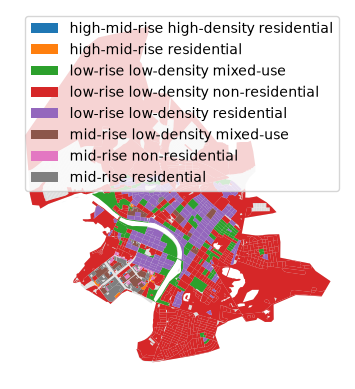

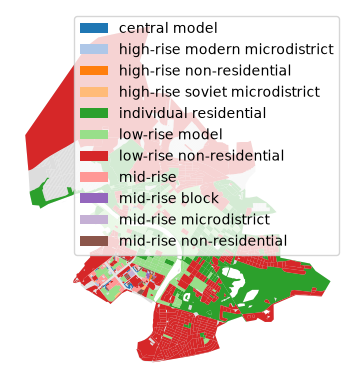

In [ ]:
if RUN_ANALYSIS:
    buildings_blocks["site_area"] = buildings_blocks.area
    density_df = calculate_density_indicators(buildings_blocks)
    density_df = density_df.rename_axis(index="block_id").reindex(blocks.index)
    DENSITY_FILE = DATA_DIR / "density_indicators.csv"
    density_df.to_csv(DENSITY_FILE)

    spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
    strelka_df = get_strelka_morphotypes(density_df)

    height_labels_ru = {
        "low-rise": "Малоэтажная",
        "mid-rise": "Среднеэтажная",
        "high-mid-rise": "Повышенной этажности",
        "high-rise": "Высотная",
        "tower": "Башенная",
    }
    density_labels_ru = {
        "low-density": "низкой плотности",
        "high-density": "высокой плотности",
    }
    use_labels_ru = {
        "non-residential": "нежилая",
        "mixed-use": "смешанная",
        "residential": "жилая",
    }

    def translate_spacematrix_morphotype(value):
        if pd.isna(value):
            return "Нет данных"
        value = str(value)
        height = next(
            (label for source, label in height_labels_ru.items() if value.startswith(source)),
            "Застройка",
        )
        density = next(
            (label for source, label in density_labels_ru.items() if source in value),
            None,
        )
        use = next(
            (label for source, label in use_labels_ru.items() if source in value),
            None,
        )
        return ", ".join(part for part in [height, density, use] if part)

    strelka_labels_ru = {
        "low-rise non-residential": "Малоэтажная нежилая застройка",
        "individual residential": "Индивидуальная жилая застройка",
        "low-rise model": "Малоэтажная модель застройки",
        "mid-rise": "Среднеэтажная застройка",
        "mid-rise non-residential": "Среднеэтажная нежилая застройка",
        "mid-rise microdistrict": "Среднеэтажный микрорайон",
        "mid-rise block": "Среднеэтажный квартал",
        "central model": "Центральная модель застройки",
        "high-rise non-residential": "Высотная нежилая застройка",
        "high-rise soviet microdistrict": "Высотный советский микрорайон",
        "high-rise modern microdistrict": "Высотный современный микрорайон",
    }
    spacematrix_df["morphotype_ru"] = spacematrix_df["morphotype"].map(
        translate_spacematrix_morphotype
    )
    spacematrix_clusters["morphotype_ru"] = spacematrix_clusters["morphotype"].map(
        translate_spacematrix_morphotype
    )
    strelka_df["morphotype_ru"] = strelka_df["morphotype"].map(
        lambda value: strelka_labels_ru.get(value, "Нет данных")
    )

    print("Показатели плотности:", density_df.shape)
    display(density_df.head())
    print("Морфотипы Spacematrix по кварталам:")
    display(spacematrix_df[["l", "fsi", "mxi", "cluster", "morphotype", "morphotype_ru"]].head())
    print("Центры кластеров Spacematrix:")
    display(spacematrix_clusters.head())
    print("Морфотипы Стрелки:")
    display(strelka_df[["l", "fsi", "mxi", "morphotype", "morphotype_ru"]].head())

    ax = blocks.plot(color="#dddddd")
    blocks.join(spacematrix_df[["morphotype_ru"]]).plot(
        "morphotype_ru", legend=True, legend_kwds={"title": "Морфотип Spacematrix"}, ax=ax
    ).set_axis_off()
    ax = blocks.plot(color="#dddddd")
    blocks.join(strelka_df[["morphotype_ru"]]).plot(
        "morphotype_ru", legend=True, legend_kwds={"title": "Морфотип Стрелки"}, ax=ax
    ).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

### Доступность территории

Рассчитывается взвешенная площадью доступность с помощью `area_accessibility(acc_mx, buildings_blocks)`. Результат привязывается к кварталам, чтобы увидеть, какие участки лучше обеспечены по пешеходному времени от всех остальных кварталов.

In [24]:
if RUN_ANALYSIS:
    area_acc = area_accessibility(acc_mx, buildings_blocks)
    area_acc = area_acc.reindex(blocks.index)
    AREA_ACCESSIBILITY_FILE = DATA_DIR / "area_accessibility.csv"
    area_acc.to_csv(AREA_ACCESSIBILITY_FILE)
    blocks_with_access = blocks.join(area_acc)
    print("Взвешенное по площади время до квартала (минуты):")
    display(area_acc.describe())
    blocks_with_access.plot("area_accessibility", legend=True).set_axis_off()
else:
    print("Пауза: включите RUN_ANALYSIS только после согласования метрик.")

NameError: name 'acc_mx' is not defined

### Финальный слой и проверка

После расчётов объединяются итоговые слои кварталов, обеспеченности, плотности, морфотипов и доступности. Набор сохраняется как GeoJSON и CSV; затем можно быстро проверить размеры и отсутствие дубликатов по `block_id`.

In [25]:
if RUN_ANALYSIS:
    building_summary = buildings_blocks[["population", "objects_count"]].rename(
        columns={
            "population": "building_population_estimate",
            "objects_count": "building_objects_count",
        }
    )
    school_summary = schools_blocks[["objects_count"]].rename(
        columns={"objects_count": "school_objects_count"}
    )
    spacematrix_result = spacematrix_df[["morphotype"]].rename(
        columns={"morphotype": "spacematrix_morphotype"}
    )
    strelka_result = strelka_df[["morphotype"]].rename(
        columns={"morphotype": "strelka_morphotype"}
    )
    density_columns = [
        "site_area", "footprint_area", "build_floor_area", "living_area",
        "non_living_area", "fsi", "gsi", "mxi", "l", "osr",
        "share_living", "share_non_living",
    ]
    final_layer = (
        blocks.join(building_summary)
        .join(school_summary)
        .join(provision_df)
        .join(density_df[density_columns])
        .join(spacematrix_result)
        .join(strelka_result)
        .join(area_acc)
    )
    final_layer.index.name = "block_id"
    FINAL_GEOJSON_FILE = DATA_DIR / "minusinsk_pipeline_results.geojson"
    FINAL_CSV_FILE = DATA_DIR / "minusinsk_pipeline_results.csv"
    save_geojson(final_layer, FINAL_GEOJSON_FILE)
    final_layer.drop(columns="geometry").to_csv(FINAL_CSV_FILE)

    final_checks = {
        "blocks": len(blocks),
        "block_id_unique": blocks.index.is_unique,
        "final_rows": len(final_layer),
        "final_columns": len(final_layer.columns),
        "required_outputs_present": all(
            column in final_layer.columns
            for column in [
                "land_use", "provision_strong", "fsi", "gsi", "mxi", "l",
                "osr", "spacematrix_morphotype", "strelka_morphotype",
                "area_accessibility",
            ]
        ),
    }
    print("Итоговая сводка:")
    for key, value in final_checks.items():
        print(f"- {key}: {value}")
    print("Итоговые файлы:", FINAL_GEOJSON_FILE, "и", FINAL_CSV_FILE)
    if blocks.index.has_duplicates or not final_checks["required_outputs_present"]:
        raise ValueError("Проверьте block_id и состав итогового слоя.")
    display(final_layer.head())
else:
    print("Пауза: RUN_ANALYSIS = False. Расчёты не выполняются.")

KeyError: "['objects_count'] not in index"